In [10]:
# The aim of this example is to predict the geopotential at the 500hPa pressure level in the atmosphere and compare your solution with the benchmark dataset.
# This variable is important for identifying weather systems such as cyclones and anticyclones.

# Import packages
import xarray as xr # numerical arrays
import numpy as np # multi-dimentional labels
!pip install cartopy
import matplotlib.pyplot as plt
import cartopy.crs as ccrs # to add coasts and projection

# Load in the necessary python packages to train a neural network
import tensorflow.keras as keras  # high-level API inside Tensorflow for NN
import tensorflow as tf # Google's deep learning framework

In [11]:
try:
  !wget https://get.ecmwf.int/repository/mooc-machine-learning-weather-climate/geopotential_500_5.625deg.zip
except:
  !wget -no-check-certificate "https://dataserv.ub.tum.de/s/m1524895/download?path=%2F5.625deg%2Fgeopotential_500&files=geopotential_500_5.625deg.zip" -O geopotential_500_5.625deg.zip

--2026-10-28 15:40:06--  https://get.ecmwf.int/repository/mooc-machine-learning-weather-climate/geopotential_500_5.625deg.zip
Resolving get.ecmwf.int (get.ecmwf.int)... 136.156.238.204
Connecting to get.ecmwf.int (get.ecmwf.int)|136.156.238.204|:443... connected.
HTTP request sent, awaiting response... 302 Moved Temporarily
Location: https://sites.ecmwf.int/repository/mooc-ml-weather-climate/geopotential_500_5.625deg.zip [following]
--2026-10-28 15:40:06--  https://sites.ecmwf.int/repository/mooc-ml-weather-climate/geopotential_500_5.625deg.zip
Resolving sites.ecmwf.int (sites.ecmwf.int)... 136.156.238.204
Connecting to sites.ecmwf.int (sites.ecmwf.int)|136.156.238.204|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1532774663 (1.4G) [application/zip]
Saving to: ‘geopotential_500_5.625deg.zip.1’

geopotential_500_5. 100%[===================>]   1.43G  15.8MB/s    in 91s     

2026-10-28 15:41:38 (16.1 MB/s) - ‘geopotential_500_5.625deg.zip.1’ saved [1532774663

In [12]:
from google.colab import drive
drive.mount('/content/drive')
!cp geopotential_500_5.625deg.zip /content/drive/MyDrive/

Mounted at /content/drive


In [13]:
# unzip data
!unzip geopotential_500_5.625deg.zip

Archive:  geopotential_500_5.625deg.zip
  inflating: geopotential_500hPa_1979_5.625deg.nc  
  inflating: geopotential_500hPa_1980_5.625deg.nc  
  inflating: geopotential_500hPa_1981_5.625deg.nc  
  inflating: geopotential_500hPa_1982_5.625deg.nc  
  inflating: geopotential_500hPa_1983_5.625deg.nc  
  inflating: geopotential_500hPa_1984_5.625deg.nc  
  inflating: geopotential_500hPa_1985_5.625deg.nc  
  inflating: geopotential_500hPa_1986_5.625deg.nc  
  inflating: geopotential_500hPa_1987_5.625deg.nc  
  inflating: geopotential_500hPa_1988_5.625deg.nc  
  inflating: geopotential_500hPa_1989_5.625deg.nc  
  inflating: geopotential_500hPa_1990_5.625deg.nc  
  inflating: geopotential_500hPa_1991_5.625deg.nc  
  inflating: geopotential_500hPa_1992_5.625deg.nc  
  inflating: geopotential_500hPa_1993_5.625deg.nc  
  inflating: geopotential_500hPa_1994_5.625deg.nc  
  inflating: geopotential_500hPa_1995_5.625deg.nc  
  inflating: geopotential_500hPa_1996_5.625deg.nc  
  inflating: geopotentia

In [14]:
# xr.open_dataset only read instead of loading
# geopotential_500*.nc，*是通配符，批量打开所有类似开头的文件
# combine = 'by_coords', 按坐标（此处是时间）将素有文件自动连接成连续的数据集。by_coords代表根据默认值
# other options: combine = 'nested', contact_dim = 'time'. or contact_dim = 'member'   按给定的时顺序时间或member来拼接
# .isel(time=slice(None, None, 12)) 按位置索引，每隔12个时间步取一个。slice(starting point, ending point, length of step)
# dimention name of time, lat, lon already exist in the xrray, so it can be found if I name it correctly.
# other examples: z500 = z500.isel(lat = slice (0, 16)) extract the first 16 latitudes.
z500 = xr.open_mfdataset('geopotential_500*.nc', combine='by_coords').isel(time=slice(None, None, 12))
z500

<xarray.Dataset> Size: 240MB
Dimensions:  (time: 29220, lat: 32, lon: 64)
Coordinates:
  * time     (time) datetime64[ns] 234kB 1979-01-01 ... 2018-12-31T12:00:00
  * lat      (lat) float64 256B -87.19 -81.56 -75.94 ... 75.94 81.56 87.19
  * lon      (lon) float64 512B 0.0 5.625 11.25 16.88 ... 343.1 348.8 354.4
    level    int32 4B 500
Data variables:
    z        (time, lat, lon) float32 239MB dask.array<chunksize=(730, 32, 64), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.6
    history:      2019-11-10 20:33:23 GMT by grib_to_netcdf-2.14.0: /opt/ecmw...

In [15]:
# load data into memory to speed up accessing data.
z500.load()

<xarray.Dataset> Size: 240MB
Dimensions:  (time: 29220, lat: 32, lon: 64)
Coordinates:
  * time     (time) datetime64[ns] 234kB 1979-01-01 ... 2018-12-31T12:00:00
  * lat      (lat) float64 256B -87.19 -81.56 -75.94 ... 75.94 81.56 87.19
  * lon      (lon) float64 512B 0.0 5.625 11.25 16.88 ... 343.1 348.8 354.4
    level    int32 4B 500
Data variables:
    z        (time, lat, lon) float32 239MB 5.156e+04 5.158e+04 ... 4.864e+04
Attributes:
    Conventions:  CF-1.6
    history:      2019-11-10 20:33:23 GMT by grib_to_netcdf-2.14.0: /opt/ecmw...

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


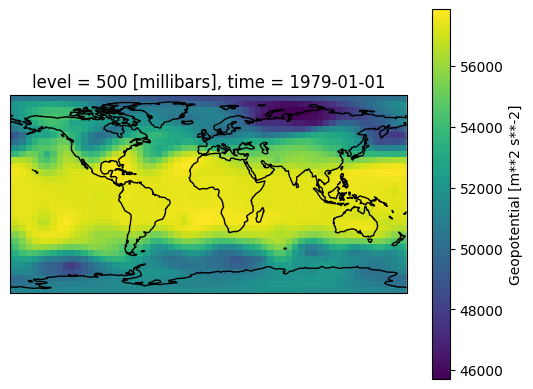

In [16]:
# plot the geopotential at an example date-time
ax = plt.axes(projection = ccrs.PlateCarree()) # 等距圆柱投影(equirectangular)
z500.z.isel(time=0).plot(ax = ax, transform = ccrs.PlateCarree()); # extract variable (geopotential height z) from z500, time = 0
ax.coastlines()

Compute baselines: use the training time period of 1979 to 2015 to compute the climatology for each day of the year.

In [17]:
# training dataset selection
train_years = slice ('1979', '2015')
# validation dataset selection (this dataset helps with overfitting)
# 训练和验证数据集同时误差下降-->模式在学习规律；训练误差下降但验证误差上升-->模式过拟合
valid_years = slice ('2016', '2016')
# test dataset selection
test_years = slice ('2017', '2018')

In [18]:
def computed_weighted_rmse(fc, gt): # 定义计算RMSE的函数，输入:forecast and ground truth
  """Error metric to compute the area averaged RMSE"""
  error = fc - gt
  weights_lat = np.cos(np.deg2rad(error.lat))
  # np.deg2rad 把纬度从角度转成弧度,再取余弦。在经纬度网格上,每个格子的经纬度间隔相同,但实际面积随纬度变化:
  # 赤道附近的格子面积最大,越往两极越小,面积大约与 cos(纬度) 成正比。
  # 乘上cos(纬度)的权重,就能让每个格点的贡献与它代表的真实面积相符
  weights_lat /= weights_lat.mean() # /= 代表除以后再赋值给自己。
  rmse = np.sqrt(((error))**2 * weights_lat).mean(['time', 'lat', 'lon'])
  return rmse

In [19]:
# consider two baselines: persistence and the climatology


基准是不需要任何模型，用最简单的方法就能得到的预报，从而为预报模型提供参照标准。
1. 持续性预报（persistence）：假设天气不变，今天和5天后完全一样。惩罚不做任何演变的预报
2. 气候态预报（climatology）:假设今天的预报就是历史上同一天的气候平均态。惩罚只做气候平均态预报的模式。


In [20]:
# pick the forecast lead time
lead_time_steps = 10 # 5 day forecast

# compute persistent forecast
# .sel 是xrray中按照坐标值选取数据的方法，来自select，可以直接用真坐标值来选
# e.g. z500.sel(time='2017-10-01T00'); z500.sel(lat=slice(20,60)); z500.sel(lat=31.2, lon=121.5, method='nearest');
persistence_fc = z500.sel(time=test_years).isel(time=slice(0, -lead_time_steps))
# np.timedelta64 用64位整数记录有多少delta;
# astype转换数据类型为纳秒，xarray and pandas的默认格式是纳秒
# persistence_fc.time只读，persistence_fc['time']是同时可读和可写
persistence_fc['time'] = persistence_fc.time + np.timedelta64(lead_time_steps*12,'h').astype('timedelta64[ns]')

# target data
target = z500.sel(time=test_years)['z']
# compute RMSE
computed_weighted_rmse(persistence_fc, target)


<xarray.Dataset> Size: 12B
Dimensions:  ()
Coordinates:
    level    int32 4B 500
Data variables:
    z        float64 8B 678.6
Attributes:
    Conventions:    CF-1.6
    history:        2019-11-10 20:33:23 GMT by grib_to_netcdf-2.14.0: /opt/ec...
    units:          m**2 s**-2
    long_name:      Geopotential
    standard_name:  geopotential

In [21]:
# calculate climatology
# groupby('time.dayofyear') 按一年的第几天分组，总共得到366个数值。
# 如果是按年分组，则是time.year
clim = z500.sel(time=train_years).groupby('time.dayofyear').mean()
# compute RMSE
# z500.sel(time=test_years)选出测试期的数据，.time.进一步选择时间坐标
# dt.dayofyear dt是时间工具箱的入口，dayofyear是选取标准。
# 例如 time.dt.year; time.dt.season; time.dt.month
computed_weighted_rmse(clim.sel(dayofyear=z500.sel(time=test_years).time.dt.dayofyear), z500)

<xarray.Dataset> Size: 12B
Dimensions:  ()
Coordinates:
    level    int32 4B 500
Data variables:
    z        float64 8B 560.5
Attributes:
    Conventions:  CF-1.6
    history:      2019-11-10 20:33:23 GMT by grib_to_netcdf-2.14.0: /opt/ecmw...

Train a simple CNN: use

In [22]:
def get_train_valid_test_dataset(lead_steps, z500_dataset):
  # split train, valid and test dataset
  train_data = z500_dataset.sel(time=train_years)
  valid_data = z500_dataset.sel(time=valid_years)
  test_data = z500_dataset.sel(time=test_years)

  # normalize the data using the mean and standard deviation of the training data
  mean = train_data.mean()
  std = train_data.std()
  train_data = (train_data - mean) / std
  valid_data = (valid_data - mean) / std
  test_data = (test_data - mean) / std

  # extract numerical value from xarray Dataset because TensorFlow only recognize numpy
  mean = mean['z'].values
  std = std['z'].values

  # create inputs and outputs that are shifted by lead_Steps
  # value[..., none] 保留原有维度的同时增加新的一维
  # .isel vs .sel 前者是按坐标选取，后者是按照标签选取
  # .isel（None, -lead_steps） 是选取起始时间到倒数5天前。
  # alternative way using .sel
  # X_train = train_data.z.sel(time=slice(None, train_data.time[-lead_steps-1])).values[..., None]
  X_train = train_data.z.isel(time=slice(None, -lead_steps)).values[..., None]
  Y_train = train_data.z.isel(time=slice(lead_steps, None)).values[..., None]
  X_valid = valid_data.z.isel(time=slice(None, -lead_steps)).values[..., None]
  Y_valid = valid_data.z.isel(time=slice(lead_steps, None)).values[..., None]
  X_test = test_data.z.isel(time=slice(None, -lead_steps)).values[..., None]
  Y_test = test_data.z.isel(time=slice(lead_steps, None)).values[..., None]
  return X_train, Y_train, X_valid, Y_valid, X_test, Y_test, mean, std


In [23]:
X_train, Y_train, X_valid, Y_valid, X_test, Y_test, mean, std = get_train_valid_test_dataset(lead_time_steps, z500)
print(X_train.shape)  # 检查每个维度的大小，比如(27018, 32, 64, 1)    X_train
print(Y_train.shape)
print(X_valid.shape)
print(Y_valid.shape)
print(X_test.shape)
print(Y_test.shape)

(27018, 32, 64, 1)
(27018, 32, 64, 1)
(722, 32, 64, 1)
(722, 32, 64, 1)
(1450, 32, 64, 1)
(1450, 32, 64, 1)


Build a convolutional neural network
卷积的核心假设：一个格点的未来主要受周围格点影响。
Conv2D(32,5,padding='same')
5×5是设置滑动窗口大小。32是用32个不同的卷积核，得到32张输出图，每个卷积核学会识别一种模式。
padding = 'same'是在场的边缘补零，让输出保持32×64的大小不变。
ELU=Expotential Linear Unit（指数线性单元）是一种激活函数。Slightly smoother alternative to ReLU


In [24]:
# ============ 模型说明 ============
# model 是一个对象:由 keras.Sequential 创建,装着网络的所有层和权重
# Sequential = 流水线:按列表顺序装入各层,并自动首尾相连
#   上一层的输出直接成为下一层的输入,不用手动传递
#   局限:只能搭一条直线的结构,有跳跃连接或分支的网络(如 U-Net、AIFS)不适用
#
# Conv2D(卷积核数量, 窗口大小, padding='same')
#   - 卷积核:一个小的权重矩阵,在场上逐格滑动(步长1),做加权求和
#   - 卷积核的形状由我们设定,里面的数值由训练自动学习
#   - 卷积核数量 = 输出的通道数,每个卷积核学会识别一种模式
#   - padding='same':边缘补零,保持 32×64 的大小不变
#
# ELU():激活函数,给网络引入非线性
#   - 没有它,多层卷积叠加等价于一层线性运算
#   - 正数原样保留,负数平滑地弯向 -1
#
# 最后一层 Conv2D(1, ...):压缩回1个通道,输出一张 z500 预报场
#   - 不加激活函数,因为是回归问题,输出可以是任意实数
#
# 数据流:(32,64,1) → (32,64,32) → (32,64,32) → (32,64,1)
#
# 后续步骤:
#   model.build(形状)  → 告诉模型输入形状,创建并随机初始化权重
#   model.compile(...)  → 设定优化器(Adam,学习率1e-4)和损失函数(MSE)
#   model.fit(X, Y, ...) → 训练:用 X 预测,与 Y 比较,调整权重
#   model.predict(X)  → 用训练好的权重做预报
# ==================================

model = keras.Sequential ([
    keras.layers.Conv2D(32, 5, padding='same'),
    keras.layers.ELU(),
    keras.layers.Conv2D(32, 5, padding='same'),
    keras.layers.ELU(),
    keras.layers.Conv2D(1, 5, padding='same'),
])

build the model using an example batch and compile it. As an optimizer, we will use the standard Adam optimizer: Kingma, D. P., & Ba, J. (2014). Adam: A method for stochastic optimization. arXiv preprint arXiv:1412.6980.

In [25]:
model.build(X_train[:32].shape)
model.compile(keras.optimizers.Adam(1e-4), 'mse')

In [26]:
# check the shape of the model
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (32, 32, 64, 32)       │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ elu_2 (ELU)                     │ (32, 32, 64, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (32, 32, 64, 32)       │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ elu_3 (ELU)                     │ (32, 32, 64, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (32, 32, 64, 1)        │           801 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,265 (106.50 KB)

 Trainable params: 27,265 (106.50 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# Finally we can fit the model
# For each epoch, the entire training dataset has passed through the neural network exactly once
# Each epoch should take about 10s
# 每次送入32个样本，所有训练样本完整过15遍，同上需要结合验证集的val_loss来判断合适停止
model.fit(X_train, Y_train, batch_size=32, epochs=15)


Epoch 1/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 544s 642ms/step - loss: 0.0154
Epoch 2/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 511s 605ms/step - loss: 0.0024
Epoch 3/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 560s 663ms/step - loss: 0.0021
Epoch 4/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 517s 609ms/step - loss: 0.0019
Epoch 5/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 547s 591ms/step - loss: 0.0018
Epoch 6/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 510s 604ms/step - loss: 0.0017
Epoch 7/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 504s 596ms/step - loss: 0.0016
Epoch 8/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 507s 601ms/step - loss: 0.0016
Epoch 9/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 560s 598ms/step - loss: 0.0016
Epoch 10/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 500s 592ms/step - loss: 0.0016
Epoch 11/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 492s 581ms/step - loss: 0.0015
Epoch 12/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 508s 588ms/step - loss: 0.0015
Epoch 13/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 493s 584ms/step - loss: 0.0015
Epoch 14/15
845/845 ━━━━━━━━━━━━━━━━━━━━ 503s 585ms/step - loss: 0.0015
E

In [28]:
# Convert predictions back to xarray
# 对X_test降维，删掉通道维度，同时copy一份避免pred_test和X_test用同一个内存空间
pred_test = X_test[:, :, :, 0].copy()
# 用model进行预报，squeeze()去掉所有长度为1的维度，也就是通道维度
# 可以直接用第二句，不需要上一句（只是作为维度检查）
pred_test[:] = model.predict(X_test).squeeze()

46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 163ms/step


For network training we normalized the data by subtracting the mean and dividing by the standard deviation. To evaluate the predictions, we now need to un-normalize the data using the mean and standard deviation we used to normalize it. Then we can compute the RMSE of the predictions.

In [29]:
# Unnormalize
pred_test = pred_test * std + mean
# compute RMSE
computed_weighted_rmse(pred_test, target.isel(time=slice(lead_time_steps, None)))

<xarray.DataArray ()> Size: 8B
array(578.47226788)
Coordinates:
    level    int32 4B 500
Attributes:
    units:          m**2 s**-2
    long_name:      Geopotential
    standard_name:  geopotential

How does the skill compare to the climatology?

It is always important to visualize your models predictions. Here we take a time from the test period and visualize the ground truth, the climatology and the neural networks' predictions. What do you notice? How about if you try a different time?

Text(0.5, 1.0, 'Prediction')

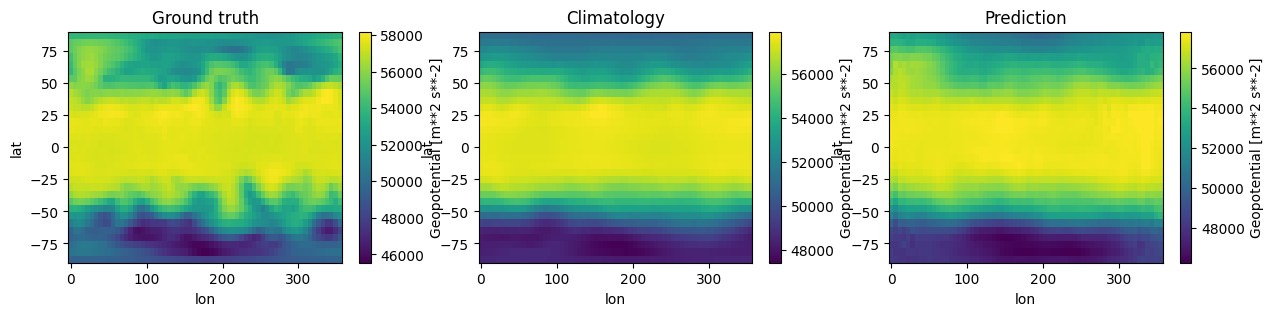

In [30]:
# Note first you need to modify your predictions so they are an xarray instead of a numpy array
# This way you can access the latitude, longitude and time for each point in the array

# We do this by taking a copy of the original z500 object which has the correct time,
# latitude and longitude, and replacing the data in this array with the predictions
# 第一句是借用测试期真值的标签做容器,去掉前10个时次，第二句是把test数据放进去
pred_xarray = z500.z.sel(time=test_years).isel(time=slice(lead_time_steps, None)).copy()
pred_xarray.data = pred_test

import matplotlib.pyplot as plt
# 定义要画的时刻，随机挑选来看预报效果
t = xr.DataArray(np.datetime64('2017-10-01T00'))
# 创建有三个子图的画布一行三列，每张图15*3英寸
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 3))

z500.z.sel(time=t).plot(ax=ax1) # 选取预报时刻的z500真值
ax1.set_title('Ground truth')

# clim没有time维度，只有1-366个平均值
clim.z.sel(dayofyear=t.dt.dayofyear).plot(ax=ax2)
ax2.set_title('Climatology')

pred_xarray.sel(time=t).plot(ax=ax3)
ax3.set_title('Prediction')


The model we built isn't particularly good. How could we make it better? Here are some ideas to try.

Make the neural net bigger/smaller?

We provide the following function for you to easily construct a neural network with more layers:

In [ ]:
# def build_model_cnn(no_of_layers):
#    """Fully convolutional network"""
#    x = input = keras.layers.Input(shape=(32, 64, 1))
#    x = Conv2D(64, 5, padding = 'same')(x)
#    for i in range(no_of_layers):
#        x = Conv2D(64, 5, padding = 'same')(x)
#        x = tf.keras.layers.Activation('ReLU')(x)
#    output = Conv2D(1, 5, padding = 'same')(x)
#    model = tf.keras.models.Model(input, output)
#    model.compile(keras.optimizers.Adam(1e-4), 'mse')
#    print(model.summary())
#    return model
# Add more variables, for example 850hPa temperature, which is available, check: https://github.com/pangeo-data/WeatherBench
# Currently, the convolutions do not wrap around the Earth. You could implement periodic convolutions, see here.